# Лабораторная работа № 16. Классификация изображений с использованием MLP
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** получение навыков по применению MLP в задачах классификации.

**Задачи:** подготовить изображения для сети; обучить и проверить MLP; превзойти исходный baseline; подготовить файл ответов по образцу соревнований.

**Данные:** Fashion-MNIST: локальная оригинальная версия Zalando из работы № 12.

Работа выполнена по методичке *Practicum_AI_Methods.pdf*, с. 141–155. В цели исправлены только опечатки.

## 1. Локальный запуск и основные понятия
Используем прежнее окружение `rcaeval-ai` с PyTorch на CPU. Новые библиотеки устанавливать не нужно. В VS Code выбираем его ядро и выполняем **Run All**. Ноутбук не требует выполнения предыдущих работ.

Эпоха — проход по всему обучению, мини-батч — небольшая порция изображений. Модель учится по обучению; отдельная часть подбора нужна для выбора настроек и весов. Итоговый тест просматриваем после выбора. Accuracy — доля правильных ответов.

Подключаем библиотеки для файлов, таблиц и графиков.

In [1]:
from pathlib import Path
from urllib.request import urlopen, urlretrieve
from importlib.metadata import version
import copy
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

Подключаем PyTorch и методы оценки.

In [2]:
import gzip
import matplotlib
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, log_loss

Задаём пути и воспроизводимые настройки.

In [3]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab16'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 17
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
sns.set_theme(style='whitegrid')

Печатаем и сохраняем версии библиотек.

In [4]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'torch', 'Pillow']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python          3.11.17
numpy             2.2.6
pandas            2.3.3
matplotlib       3.10.9
scikit-learn      1.7.2
torch            2.14.1
Pillow           12.3.0
Name: Версия, dtype: object

162

Определяем сохранение и показ рисунков.

In [5]:
def save_show(fig, filename):
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

### 1.1. Пиксели и цветовые каналы
RGB-картинка хранится как высота × ширина × 3. В PNG может быть четвёртый канал прозрачности — alpha. У Fashion-MNIST один канал: 28×28 яркостей. Для MLP разворачиваем их в 784 признака. Значения uint8 находятся в диапазоне 0–255; после деления на 255 получаем числа 0–1.

Загружаем PNG и JPEG из примеров Matplotlib и показываем их форму.

PNG: (130, 542, 4) float32 | Диапазон: 0.0 1.0
JPEG: (600, 512, 3) uint8 | Диапазон: 0 255


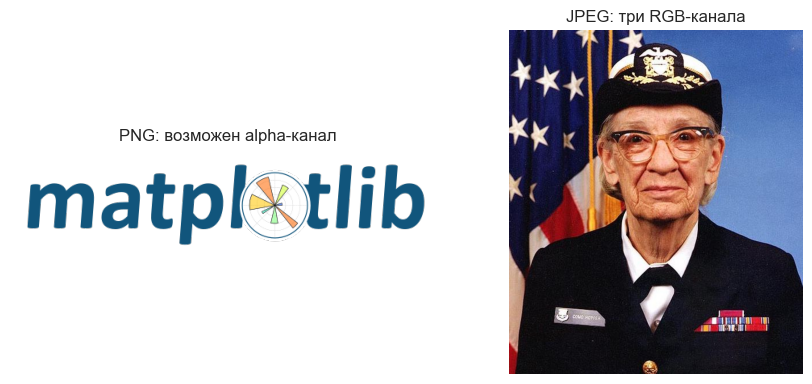

In [6]:
sample_dir = Path(matplotlib.get_data_path()) / 'sample_data'
png = plt.imread(sample_dir / 'logo2.png')
jpeg = plt.imread(sample_dir / 'grace_hopper.jpg')
print('PNG:', png.shape, png.dtype, '| Диапазон:', png.min(), png.max())
print('JPEG:', jpeg.shape, jpeg.dtype, '| Диапазон:', jpeg.min(), jpeg.max())
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, image, title in zip(axes, [png, jpeg], ['PNG: возможен alpha-канал', 'JPEG: три RGB-канала']):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()
save_show(fig, '01_image_channels.png')

В выводе видны число каналов и тип чисел. В этом способе чтения PNG представлен вещественными числами 0–1, а JPEG — целыми 0–255. Это особенность формата и загрузчика, поэтому масштаб нужно понимать перед подачей в сеть. Изображения взяты из установленного пакета Matplotlib.

## 2. Учебная задача: исходный MLP для Fashion-MNIST
### 2.1. Читаем прежние данные
Методичка использует CSV с Kaggle. У нас уже есть оригинальные IDX-файлы Zalando: 60 000 обучающих и 10 000 тестовых изображений. Используем их без повторного скачивания; один и тот же набор классов и размер изображений подходят задаче. Порядок строк этой версии не объявляем совпадающим с CSV Kaggle.

Из 60 000 строк отделяем 6000 для подбора; все модели обучаются на одинаковых 54 000. Итоговый оригинальный тест из 10 000 строк не используется при подборе. Это отличается от проверки на обучении в листинге и позволяет честно сравнить модели.

Указываем локальные файлы Fashion-MNIST.

In [7]:
FASHION = ROOT / 'data/raw/fashion'
fashion_files = ['train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz',
                 't10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz']

Читаем изображения и метки из gzip-файлов.

In [8]:
def read_images(path):
    with gzip.open(path, 'rb') as file:
        return np.frombuffer(file.read(), dtype=np.uint8, offset=16).reshape(-1, 28, 28).copy()

def read_labels(path):
    with gzip.open(path, 'rb') as file:
        return np.frombuffer(file.read(), dtype=np.uint8, offset=8).astype(np.int64)

train_images = read_images(FASHION / fashion_files[0])
train_labels = read_labels(FASHION / fashion_files[1])
test_images = read_images(FASHION / fashion_files[2])
test_labels = read_labels(FASHION / fashion_files[3])

Показываем размер и первые строки в представлении из методички.

In [9]:
class_names = ['Футболка', 'Брюки', 'Пуловер', 'Платье', 'Пальто',
               'Сандалии', 'Рубашка', 'Кроссовки', 'Сумка', 'Ботинки']
print('Обучение:', train_images.shape, '| Тест:', test_images.shape)
preview = pd.DataFrame(train_images[:5].reshape(5, -1), columns=[f'pixel{i}' for i in range(1, 785)])
preview.insert(0, 'label', train_labels[:5])
display(preview)
display(pd.Series(np.bincount(train_labels), index=class_names, name='Изображений в исходном обучении'))

Обучение: (60000, 28, 28) | Тест: (10000, 28, 28)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,1,0,0,0,...,119,114,130,76,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3,3,0,0,0,0,0,0,0,0,33,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Футболка     6000
Брюки        6000
Пуловер      6000
Платье       6000
Пальто       6000
Сандалии     6000
Рубашка      6000
Кроссовки    6000
Сумка        6000
Ботинки      6000
Name: Изображений в исходном обучении, dtype: int64

Показываем по одному настоящему изображению каждого класса.

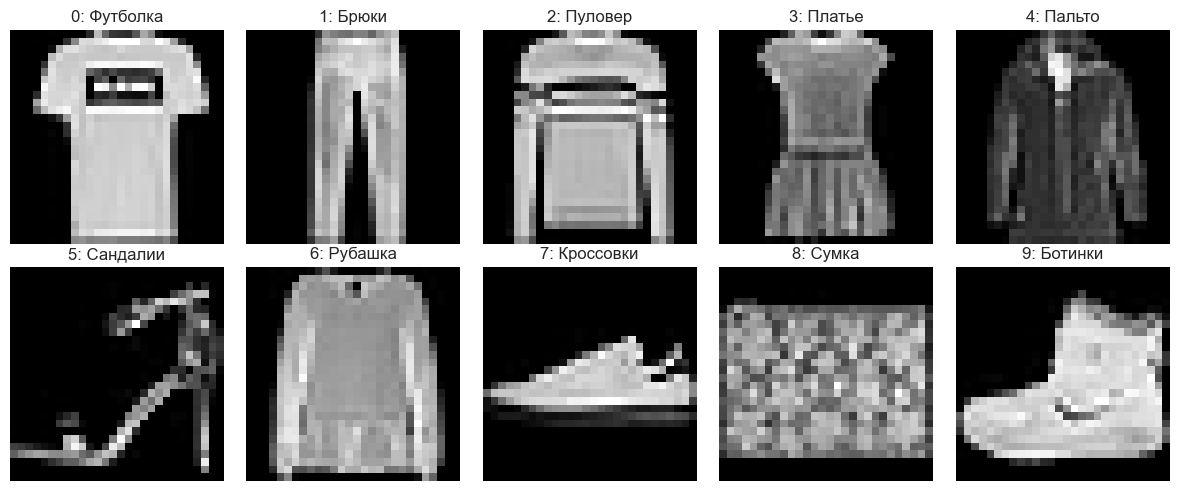

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for label, ax in enumerate(axes.flat):
    index = np.flatnonzero(train_labels == label)[0]
    ax.imshow(train_images[index], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'{label}: {class_names[label]}')
    ax.axis('off')
fig.tight_layout()
save_show(fig, '02_fashion_examples.png')

Один снимок — 784 значения яркости и отдельная правильная метка. Похожие силуэты, например рубашка и футболка, могут быть трудны для распознавания. Метка не входит в пиксельные признаки.

Отделяем часть подбора и создаём наборы тензоров.

In [11]:
train_idx, valid_idx = train_test_split(np.arange(len(train_labels)), test_size=0.1,
                                       stratify=train_labels, random_state=SEED)
train_data = TensorDataset(torch.from_numpy(train_images[train_idx]).unsqueeze(1), torch.from_numpy(train_labels[train_idx]))
valid_data = TensorDataset(torch.from_numpy(train_images[valid_idx]).unsqueeze(1), torch.from_numpy(train_labels[valid_idx]))
test_data = TensorDataset(torch.from_numpy(test_images).unsqueeze(1), torch.from_numpy(test_labels))
print('Обучение:', len(train_data), '| Подбор:', len(valid_data), '| Тест:', len(test_data))

Обучение: 54000 | Подбор: 6000 | Тест: 10000


Показываем смысл OneHot и используемые номера классов.

In [12]:
labels_example = torch.as_tensor(train_labels[:5])
print('Номера:', labels_example)
print('OneHot для просмотра:', torch.nn.functional.one_hot(labels_example, num_classes=10))

Номера: tensor([9, 0, 0, 3, 0])
OneHot для просмотра: tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
        [1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0, 0]])


На с. 149 OneHot назван обязательным. Для CrossEntropyLoss в PyTorch это не так: можно передавать целые номера классов типа long. Они дают ту же потерю, что и соответствующие OneHot-метки. Обучаемся по номерам, чтобы не хранить лишнюю матрицу. В улучшенной модели перед CrossEntropyLoss не ставим Softmax: функция уже включает нужное преобразование.

Определяем MLP с выбранными скрытыми слоями.

In [13]:
def make_mlp(hidden=(100,), dropout=0.0, final_softmax=False):
    layers, width = [nn.Flatten()], 784
    for neurons in hidden:
        layers.extend([nn.Linear(width, neurons), nn.ReLU()])
        if dropout:
            layers.append(nn.Dropout(dropout))
        width = neurons
    layers.append(nn.Linear(width, 10))
    if final_softmax:
        layers.append(nn.Softmax(dim=1))
    return nn.Sequential(*layers)

Определяем проверку потерь и accuracy по мини-батчам.

In [14]:
def evaluate(model, data, normalize, loss_fn):
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for images, labels in DataLoader(data, batch_size=512, shuffle=False):
            inputs = images.float() / (255 if normalize else 1)
            output = model(inputs)
            batch_loss = loss_fn(output, labels)
            total_loss += batch_loss.item() * (1 if loss_fn.reduction == 'sum' else len(labels))
            correct += (output.argmax(dim=1) == labels).sum().item()
    return total_loss / len(data), correct / len(data)

Определяем обучение и сохранение лучшей эпохи по части подбора.

In [15]:
def train_mlp(config):
    torch.manual_seed(SEED)
    model = make_mlp(config['hidden'], config['dropout'], config['softmax'])
    optimizer = (torch.optim.SGD(model.parameters(), lr=config['lr']) if config['optimizer'] == 'SGD'
                 else torch.optim.Adam(model.parameters(), lr=config['lr']))
    loss_fn = nn.CrossEntropyLoss(reduction=config['reduction'])
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(train_data, batch_size=config['batch'], shuffle=True, generator=generator)
    rows, best_loss, best_state, best_epoch = [], float('inf'), None, 0
    for epoch in range(1, config['epochs'] + 1):
        model.train()
        total_loss = 0.0
        for images, labels in loader:
            inputs = images.float() / (255 if config['normalize'] else 1)
            optimizer.zero_grad()
            output = model(inputs)
            loss = loss_fn(output, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * (1 if config['reduction'] == 'sum' else len(labels))
        valid_loss, valid_accuracy = evaluate(model, valid_data, config['normalize'], loss_fn)
        rows.append({'epoch': epoch, 'train_loss': total_loss / len(train_data),
                     'valid_loss': valid_loss, 'valid_accuracy': valid_accuracy})
        if valid_loss < best_loss:
            best_loss, best_state, best_epoch = valid_loss, copy.deepcopy(model.state_dict()), epoch
        if epoch == 1 or epoch % 10 == 0:
            print(f"{config['name']}: эпоха {epoch}, valid accuracy = {valid_accuracy:.3f}")
    if config['best_epoch']:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(rows), best_epoch if config['best_epoch'] else config['epochs']

Внутри каждой эпохи сеть получает все 54 000 изображений порциями, считает потери, градиенты и обновляет веса. Часть подбора проверяется без градиентов. Исходный пример сохраняет последнюю, сотую эпоху; улучшенные варианты — эпоху с наименьшими потерями на части подбора. Итоговый тест здесь не читается.

### 2.2. Повторяем baseline из листинга
Архитектура 784→100→10, ReLU, выходной Softmax, SGD с шагом 0,0001, батч 64, 100 эпох, сумма CrossEntropy и исходные пиксели 0–255 — как на с. 149–151. Сохраняем даже лишний Softmax из примера, чтобы затем показать исправление. Вместо устаревшего `size_average=False` используем `reduction='sum'`.

Это не обещание повторить числа со скриншота: здесь фиксированы seed и отдельная часть подбора, используются оригинальные файлы Zalando. Потери суммируются для градиента, но для таблиц делятся на число изображений.

Задаём и обучаем исходный baseline в течение 100 эпох.

In [16]:
baseline_config = {'name': 'Baseline методички', 'hidden': (100,), 'dropout': 0.0, 'softmax': True,
    'optimizer': 'SGD', 'lr': 0.0001, 'batch': 64, 'epochs': 100, 'reduction': 'sum',
    'normalize': False, 'best_epoch': False}
baseline_model, baseline_history, baseline_epoch = train_mlp(baseline_config)
print(baseline_model)

Baseline методички: эпоха 1, valid accuracy = 0.293


Baseline методички: эпоха 10, valid accuracy = 0.294


Baseline методички: эпоха 20, valid accuracy = 0.382


Baseline методички: эпоха 30, valid accuracy = 0.524


Baseline методички: эпоха 40, valid accuracy = 0.492


...

Baseline методички: эпоха 60, valid accuracy = 0.530


Baseline методички: эпоха 70, valid accuracy = 0.515


Baseline методички: эпоха 80, valid accuracy = 0.543


Baseline методички: эпоха 90, valid accuracy = 0.540


Baseline методички: эпоха 100, valid accuracy = 0.538
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=100, bias=True)
  (2): ReLU()
  (3): Linear(in_features=100, out_features=10, bias=True)
  (4): Softmax(dim=1)
)


Показываем обучение исходного MLP.

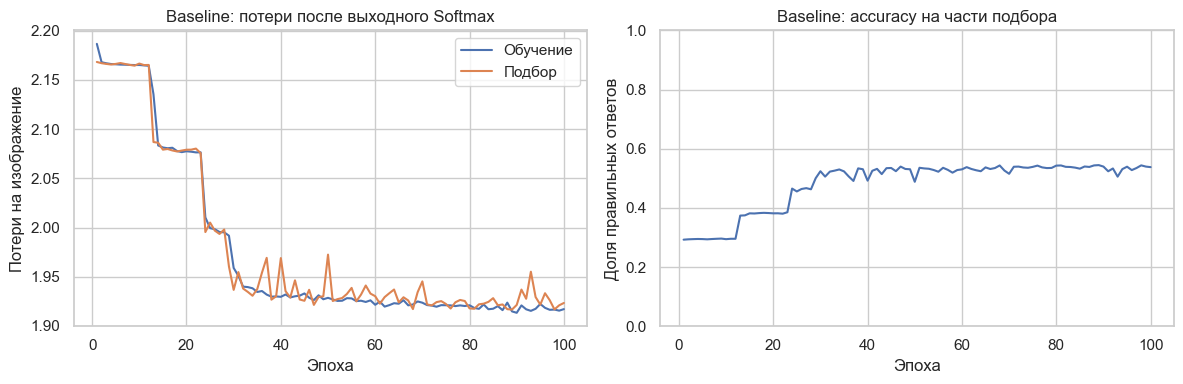

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(baseline_history.epoch, baseline_history.train_loss, label='Обучение')
axes[0].plot(baseline_history.epoch, baseline_history.valid_loss, label='Подбор')
axes[0].set(title='Baseline: потери после выходного Softmax', xlabel='Эпоха', ylabel='Потери на изображение')
axes[0].legend()
axes[1].plot(baseline_history.epoch, baseline_history.valid_accuracy)
axes[1].set(title='Baseline: accuracy на части подбора', xlabel='Эпоха', ylabel='Доля правильных ответов', ylim=(0, 1))
fig.tight_layout()
save_show(fig, '03_baseline_training.png')

Слева потери обучения и подбора исходной модели, справа — правильные ответы на части подбора. У такого baseline есть неудачные решения: большие пиксели и лишний Softmax перед CrossEntropy. Его уровень потерь нельзя напрямую сопоставлять с потерями модели, которая передаёт исходные оценки классов. Улучшение проверяем по accuracy на тех же изображениях.

## 3. Индивидуальное задание: улучшаем MLP
### 3.1. Нормировка, скрытые слои и оптимизатор
Во всех улучшенных вариантах делим пиксели на 255, убираем Softmax перед CrossEntropyLoss и используем Adam. Сравниваем 128–64 и 256–128 скрытых нейронов, dropout 0,2. Dropout случайно выключает часть активаций только при обучении и помогает меньше запоминать отдельные изображения.

Для обоих вариантов одинаковы батч 256 и 25 эпох. Это сравнение двух готовых архитектур; исправление подготовки и функции потерь отделено от исходного baseline. Выбор — максимальная accuracy части подбора, при равенстве меньшая LogLoss.

Задаём два улучшенных варианта MLP.

In [18]:
improved_configs = [
    {'name': 'MLP 128–64', 'hidden': (128, 64), 'dropout': 0.2, 'softmax': False,
     'optimizer': 'Adam', 'lr': 0.001, 'batch': 256, 'epochs': 25, 'reduction': 'mean',
     'normalize': True, 'best_epoch': True},
    {'name': 'MLP 256–128', 'hidden': (256, 128), 'dropout': 0.2, 'softmax': False,
     'optimizer': 'Adam', 'lr': 0.001, 'batch': 256, 'epochs': 25, 'reduction': 'mean',
     'normalize': True, 'best_epoch': True}
]

Обучаем улучшенные сети только по обучению и части подбора.

In [19]:
models = {baseline_config['name']: baseline_model}
histories = {baseline_config['name']: baseline_history}
chosen_epochs = {baseline_config['name']: baseline_epoch}
for config in improved_configs:
    model, history, epoch = train_mlp(config)
    name = config['name']
    models[name], histories[name], chosen_epochs[name] = model, history, epoch

MLP 128–64: эпоха 1, valid accuracy = 0.818


MLP 128–64: эпоха 10, valid accuracy = 0.874


MLP 128–64: эпоха 20, valid accuracy = 0.892


MLP 256–128: эпоха 1, valid accuracy = 0.839


MLP 256–128: эпоха 10, valid accuracy = 0.883


MLP 256–128: эпоха 20, valid accuracy = 0.895


Определяем получение вероятностей по мини-батчам.

In [20]:
def predict_probabilities(model, data, config):
    model.eval()
    parts = []
    with torch.no_grad():
        for images, _ in DataLoader(data, batch_size=512, shuffle=False):
            output = model(images.float() / (255 if config['normalize'] else 1))
            parts.append((output if config['softmax'] else output.softmax(dim=1)).numpy())
    return np.concatenate(parts)

Сравниваем все сети на части подбора и фиксируем выбор.

In [21]:
all_configs = [baseline_config, *improved_configs]
validation_rows = []
for config in all_configs:
    name = config['name']
    probability = predict_probabilities(models[name], valid_data, config)
    validation_rows.append({'name': name, 'epoch': chosen_epochs[name],
        'parameters': sum(p.numel() for p in models[name].parameters()),
        'valid_accuracy': accuracy_score(train_labels[valid_idx], probability.argmax(axis=1)),
        'valid_logloss': log_loss(train_labels[valid_idx], probability, labels=np.arange(10))})
validation_table = pd.DataFrame(validation_rows)
display(validation_table)
improved_names = [config['name'] for config in improved_configs]
best_name = validation_table[validation_table.name.isin(improved_names)].sort_values(
    ['valid_accuracy', 'valid_logloss'], ascending=[False, True]).iloc[0]['name']
best_config = next(config for config in improved_configs if config['name'] == best_name)
print('Выбрано до просмотра теста:', best_name)

,name,epoch,parameters,valid_accuracy,valid_logloss
0,Baseline методички,100,79510,0.537833,7.311825
1,MLP 128–64,25,109386,0.889833,0.303396
2,MLP 256–128,25,235146,0.898167,0.296592


Выбрано до просмотра теста: MLP 256–128


Показываем обучение улучшенных вариантов.

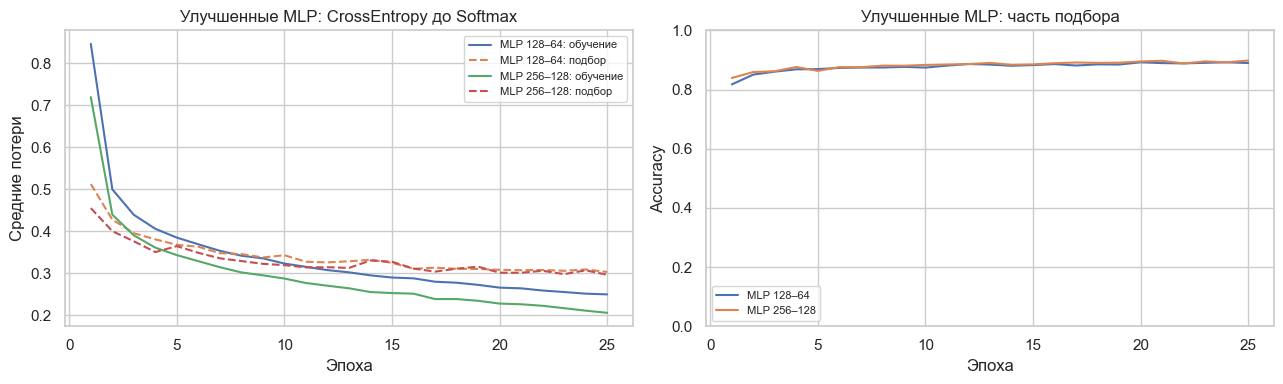

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for config in improved_configs:
    name, history = config['name'], histories[config['name']]
    axes[0].plot(history.epoch, history.train_loss, label=name + ': обучение')
    axes[0].plot(history.epoch, history.valid_loss, '--', label=name + ': подбор')
    axes[1].plot(history.epoch, history.valid_accuracy, label=name)
axes[0].set(title='Улучшенные MLP: CrossEntropy до Softmax', xlabel='Эпоха', ylabel='Средние потери')
axes[1].set(title='Улучшенные MLP: часть подбора', xlabel='Эпоха', ylabel='Accuracy', ylim=(0, 1))
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
save_show(fig, '04_improved_training.png')

Сплошные линии слева относятся к обучению, пунктирные — к части подбора. Если потери обучения падают, а проверочные растут, сеть начинает запоминать особенности обучения. Справа видно качество на тех же проверочных изображениях. Поэтому сохраняем не просто последнюю, а лучшую по проверочным потерям эпоху каждого улучшенного варианта.

### 3.2. Итоговый тест и сравнение с baseline
Настройки и веса уже выбраны. Теперь один раз оцениваем исходный baseline и выбранный MLP на оригинальных 10 000 тестовых изображений. Тестовые метки используются только для этой оценки, а не для дообучения.

Проверяем baseline и выбранный MLP на одних тестовых изображениях.

In [23]:
test_probabilities, test_predictions, test_rows = {}, {}, []
for config in [baseline_config, best_config]:
    name = config['name']
    probability = predict_probabilities(models[name], test_data, config)
    predicted = probability.argmax(axis=1)
    test_probabilities[name], test_predictions[name] = probability, predicted
    test_rows.append({'name': name, 'test_accuracy': accuracy_score(test_labels, predicted),
                       'test_logloss': log_loss(test_labels, probability, labels=np.arange(10))})
test_table = pd.DataFrame(test_rows)
display(test_table)
print('Разница accuracy выбранной модели и baseline:', test_table.test_accuracy.iloc[1] - test_table.test_accuracy.iloc[0])

,name,test_accuracy,test_logloss
0,Baseline методички,0.5330,7.382416
1,MLP 256–128,0.8947,0.307995


Разница accuracy выбранной модели и baseline: 0.3617


Показываем ошибки двух сетей по всем десяти классам.

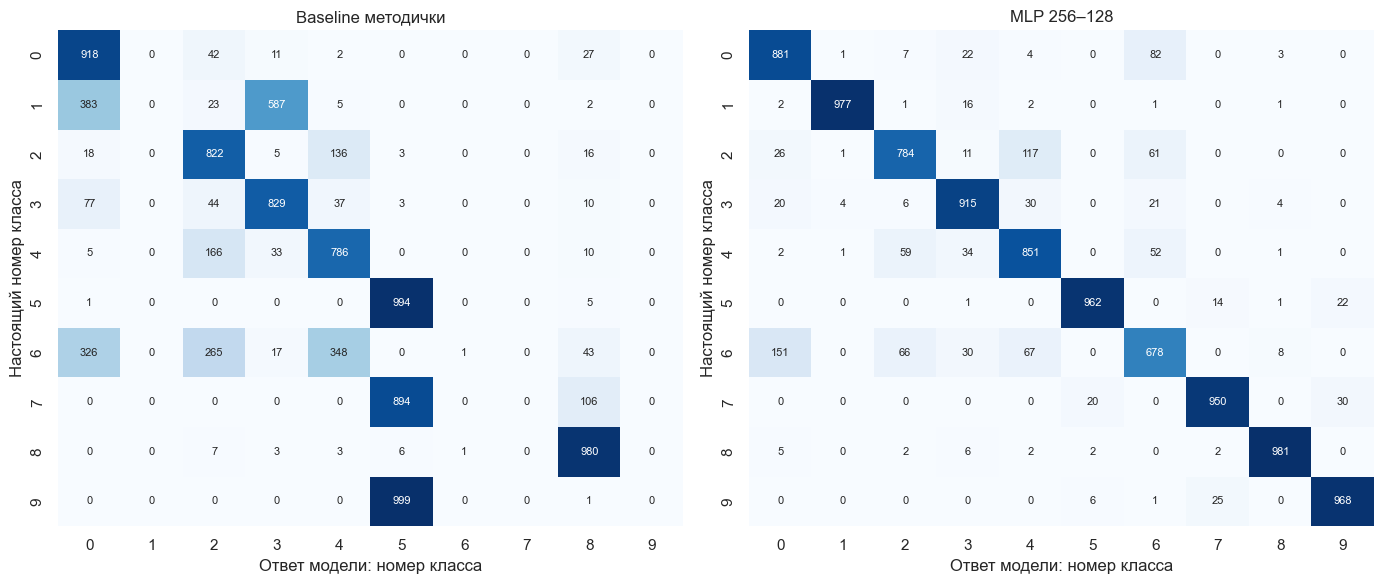

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, [baseline_config['name'], best_name]):
    cm = confusion_matrix(test_labels, test_predictions[name], labels=np.arange(10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, annot_kws={'fontsize': 8})
    ax.set(title=name, xlabel='Ответ модели: номер класса', ylabel='Настоящий номер класса')
fig.tight_layout()
save_show(fig, '05_test_confusion.png')

На диагонали — правильные ответы, в остальных клетках — перепутанные виды одежды. Номера расшифрованы в начале ноутбука. Если столбец класса почти пуст, сеть редко выбирает этот ответ. Это полезнее одной общей accuracy: можно заметить, какие именно вещи она не распознаёт.

Сравниваем долю распознанных изображений каждого настоящего класса.

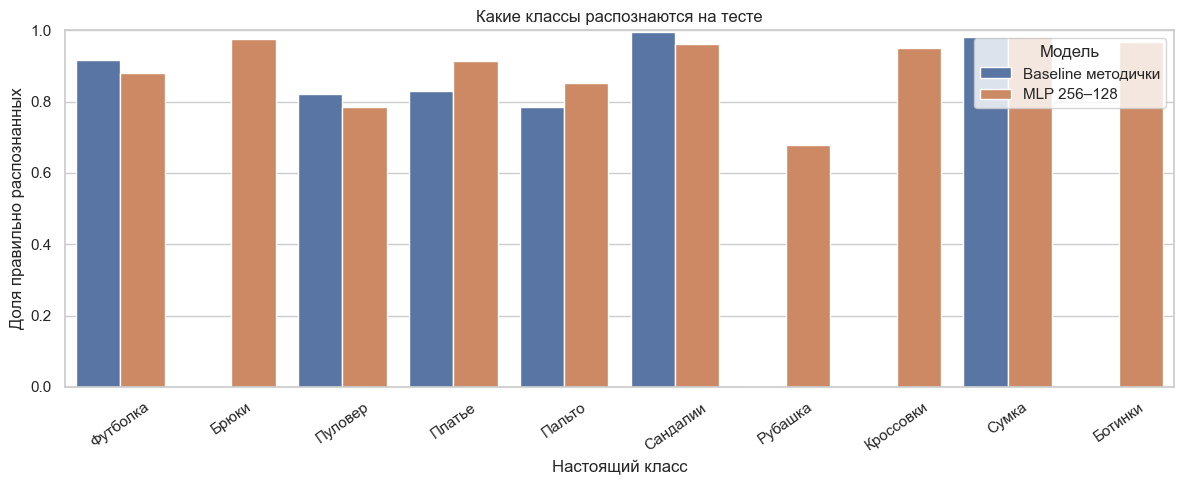

In [25]:
recall_rows = []
for name in [baseline_config['name'], best_name]:
    cm = confusion_matrix(test_labels, test_predictions[name], labels=np.arange(10))
    for label, recall in enumerate(np.diag(cm) / cm.sum(axis=1)):
        recall_rows.append({'model': name, 'class': class_names[label], 'recall': recall})
recall_table = pd.DataFrame(recall_rows)
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=recall_table, x='class', y='recall', hue='model', ax=ax)
ax.set(title='Какие классы распознаются на тесте', xlabel='Настоящий класс', ylabel='Доля правильно распознанных', ylim=(0, 1))
ax.tick_params(axis='x', rotation=35)
ax.legend(title='Модель')
fig.tight_layout()
save_show(fig, '06_class_recall.png')

Для каждого вида одежды столбик показывает, какая доля настоящих изображений этого вида распознана верно. Это recall класса, а не доля его среди всех ответов. Низкий столбик помогает увидеть класс, который теряется даже при достаточно высокой общей accuracy.

Рассматриваем первые восемь ошибок выбранной модели.

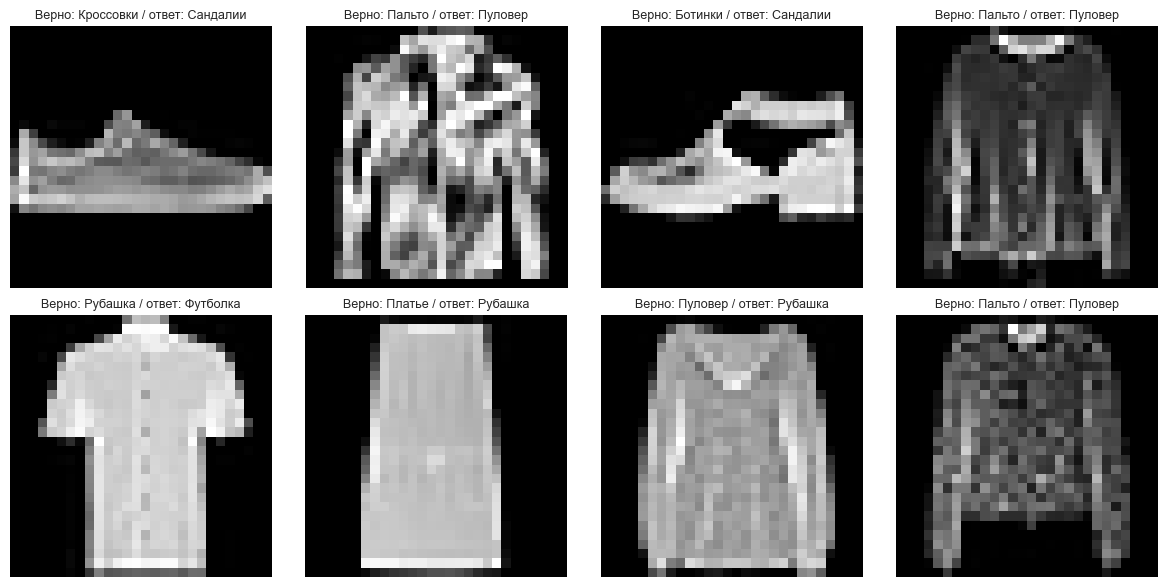

In [26]:
error_indices = np.flatnonzero(test_predictions[best_name] != test_labels)[:8]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flat:
    ax.axis('off')
for ax, index in zip(axes.flat, error_indices):
    actual, predicted = test_labels[index], test_predictions[best_name][index]
    ax.imshow(test_images[index], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Верно: {class_names[actual]} / ответ: {class_names[predicted]}', fontsize=9)
fig.tight_layout()
save_show(fig, '07_mistakes.png')

Это настоящие ошибочные ответы, выбранные по порядку тестовых строк. Подпись показывает правильный класс и ответ сети. Похожие силуэты, складки и низкое разрешение могут мешать различать одежду. По этим изображениям параметры уже не меняем.

### 3.3. Готовим CSV с ответами по примеру соревнования
Ссылка в методичке ведёт на **датасет Kaggle**, а конкретное соревнование и его `sample_submission` не указаны. Здесь отрабатываем локальный цикл: обучение, сравнение baseline и CSV с колонками `Category`, `Id`, как на с. 153.

Файлы относятся к оригинальному тесту Zalando в его исходном порядке. Для внешнего соревнования нужен именно его тест и проверка порядка Id по его образцу. Эти CSV не объявляются отправленными на Kaggle; место в рейтинге и внешний score не приписываются локальной accuracy.

Сохраняем исходные и улучшенные ответы в формате примера.

In [27]:
for name, filename in [(baseline_config['name'], 'baseline.csv'), (best_name, 'answer.csv')]:
    answers = pd.DataFrame({'Category': test_predictions[name], 'Id': np.arange(len(test_images))})
    answers.to_csv(REPORT / filename, index=False)
display(pd.read_csv(REPORT / 'answer.csv').head())

,Category,Id
0,9,0
1,2,1
2,1,2
3,1,3
4,6,4


Сохраняем сравнение, веса, источники и формируем простой текст результата.

In [28]:
validation_table.to_csv(REPORT / 'validation_metrics.csv', index=False)
test_table.to_csv(REPORT / 'test_metrics.csv', index=False)
recall_table.to_csv(REPORT / 'class_recall.csv', index=False)
for index, (name, history) in enumerate(histories.items()):
    filename = 'history_baseline.csv' if index == 0 else f'history_{index}.csv'
    history.to_csv(REPORT / filename, index=False)
pd.DataFrame({'row': np.arange(len(test_labels)), 'actual': test_labels,
              'baseline': test_predictions[baseline_config['name']], 'selected': test_predictions[best_name]}).to_csv(REPORT / 'predictions.csv', index=False)
np.savez_compressed(REPORT / 'split_indices.npz', train=train_idx, valid=valid_idx)
torch.save({'state_dict': models[best_name].state_dict(), 'config': best_config,
            'classes': class_names, 'epoch': chosen_epochs[best_name]}, REPORT / 'fashion_mlp.pt')
base_accuracy, selected_accuracy = test_table.test_accuracy.iloc[0], test_table.test_accuracy.iloc[1]
analysis = (f'Получил навыки применения MLP к классификации изображений. Обучил baseline из методички '
            f'и два улучшенных MLP. На 10 000 итоговых изображений baseline дал {base_accuracy:.1%}, '
            f'выбранный по части подбора {best_name} — {selected_accuracy:.1%}. '
            'Изучил нормировку пикселей, мини-батчи и ошибки по классам. Подготовил локальные CSV ответов; '
            'результат на внешнем соревновании не измерялся.')
display(Markdown(analysis))
(REPORT / 'analysis.md').write_text(analysis, encoding='utf-8')
summary = {'train_rows': len(train_data), 'valid_rows': len(valid_data), 'test_rows': len(test_data),
           'baseline_epochs': baseline_epoch, 'selected': best_name, 'selected_epoch': chosen_epochs[best_name],
           'test_metrics': test_table.to_dict('records'), 'validation_metrics': validation_table.to_dict('records'),
           'baseline_beaten': bool(selected_accuracy > base_accuracy),
           'figures': sorted(p.name for p in FIGURES.glob('*.png'))}
(REPORT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
sources = {'fashion_source': 'https://github.com/zalandoresearch/fashion-mnist',
           'revision': 'b2617bb6d3ffa2e429640350f613e3291e10b141',
           'sha256': {str((FASHION / name).relative_to(ROOT)): hashlib.sha256((FASHION / name).read_bytes()).hexdigest() for name in fashion_files}}
(REPORT / 'sources.json').write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding='utf-8')

Получил навыки применения MLP к классификации изображений. Обучил baseline из методички и два улучшенных MLP. На 10 000 итоговых изображений baseline дал 53.3%, выбранный по части подбора MLP 256–128 — 89.5%. Изучил нормировку пикселей, мини-батчи и ошибки по классам. Подготовил локальные CSV ответов; результат на внешнем соревновании не измерялся.

624

## 4. Заключение
Получил навыки по применению MLP в задачах классификации. Подготовил настоящие изображения Fashion-MNIST, обучил исходный и улучшенные варианты, сравнил их на отдельном тесте и разобрал ошибки по видам одежды.

Освоил нормировку пикселей, обучение мини-батчами, выбор весов по части подбора и сохранение ответов. Отработал локальные шаги подготовки CSV для соревнования. Численное сравнение с baseline приведено в тексте результата выше; локальная проверка не выдаётся за участие в конкретном рейтинге.

На отдельном тесте исходный baseline дал 53,3% правильных ответов, выбранный MLP 256–128 — 89,47%. Таким образом, baseline превзойдён на тех же 10 000 изображениях. Настройки по итоговому тесту не менялись.

## 5. Ответы на контрольные вопросы
**1. Что влияет на качество со стороны модели?**  
Архитектура, активации, начальные веса, оптимизатор, шаг обучения, размер батча, число эпох и регуляризация. Их задаёт разработчик; подходящие значения зависят от задачи.

**2. Что влияет со стороны данных?**  
Число и разнообразие примеров, качество разметки, шум, масштаб признаков и соотношение классов. Данные для проверки должны соответствовать будущему применению.

**3. Как задают сеть в PyTorch?**  
Через `nn.Sequential` — последовательность слоёв; или собственный класс `nn.Module` с методом `forward`. Внутри `forward` используют слои и функции `torch.nn.functional`.

**4. Что такое прямое и обратное распространение?**  
Прямой проход вычисляет результаты слоёв и оценки классов. `backward()` находит производные потери по весам, используя правило производной сложной функции. Веса изменяет `optimizer.step()`. Перед новым шагом накопленные градиенты обнуляют.

**5. Как устроена MLP?**  
Изображение превращается в строку пикселей, затем проходит через полносвязные скрытые слои с нелинейными активациями и выход. В Fashion-MNIST 784 входа и 10 выходных оценок. Наибольшая оценка задаёт класс.

**6. Почему нельзя бесконечно улучшать качество добавлением слоёв?**  
Растут число параметров, время обучения и риск запоминания шума. Данных может не хватить, оптимизация усложняется. Ошибки разметки и неоднозначные изображения глубина сама по себе не исправит. Проверяют качество на отдельных данных.

## 6. Источники
- Методичка *Practicum_AI_Methods.pdf*, с. 141–155.
- [Fashion-MNIST, Zalando Research](https://github.com/zalandoresearch/fashion-mnist).
- [Страница датасета Kaggle из методички](https://www.kaggle.com/datasets/zalando-research/fashionmnist).
- [PyTorch: CrossEntropyLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html).
- [PyTorch: DataLoader и TensorDataset](https://docs.pytorch.org/docs/2.14/data.html).